# Holder-space (Vasin-Serazhitnikova) unfolding of an IAEA Compendium spectrum (`unfold_vasin`)

This notebook applies the regularized approximation method of

> V. V. Vasin, T. I. Serazhitnikova, *Regular algorithm for approximation of
> irregular solutions for Fredholm integral equations of the first kind*,
> Vyčislitel'nye Tekhnologii 15(2), 2010, 15-23.

to neutron-spectrum unfolding.  The method is a Tikhonov scheme whose
stabilizer is **non-differentiable**: instead of penalizing curvature it
penalizes the Hölder (Lipschitz) seminorm, measured in the uniform norm,

$$[u]_{\mu,\infty} = \max_{i \ne j}
   \frac{|u_i - u_j|}{|x_i - x_j|^{\mu}}, \qquad 0 < \mu \le 1,$$

and it measures the data misfit in the Chebyshev norm as well:

$$\min_u \; \max_i \left| \frac{(Au)_i - b_i}{b_i} \right|
  + \alpha \left[ \tfrac12 \sum_j h_j u_j^2 + \max_j |u_j| + [u]_{\mu,\infty}
  \right], \qquad u \ge 0 .$$

Because $\Phi$ is a sum of maxima of affine functions plus one quadratic term,
the functional is minimized **exactly** here through its epigraph form as a
conic program.  The paper reaches the same minimizer with a prox-method and an
inner subgradient (or Fejér) process; at unfolding sizes that iteration needs
tens of thousands of steps to get to where the epigraph solve arrives in a few
tens of milliseconds, so the iteration is replaced by the exact solve while the
stabilizer, the discrepancy norm and the positivity constraint are kept as they
are in the article.

In [1]:
# %pip install bssunfold pandas numpy matplotlib

## 1. Detector response functions

We use the built-in GSF response functions (10 Bonner spheres, `0in` -
`18in`, 60 energy bins from 1e-9 to ~631 MeV).  The Hölder distances $d_{ij}$
are taken on the logarithmic energy grid and rescaled to unit diameter, and the
quadrature weights $h_j$ of the quadratic term are the log-energy bin widths.

Detector grid: 60 bins, 1.0e-09 - 631.0 MeV
Spheres: 0in, 2in, 3in, 5in, 6in, 8in, 10in, 12in, 15in, 18in


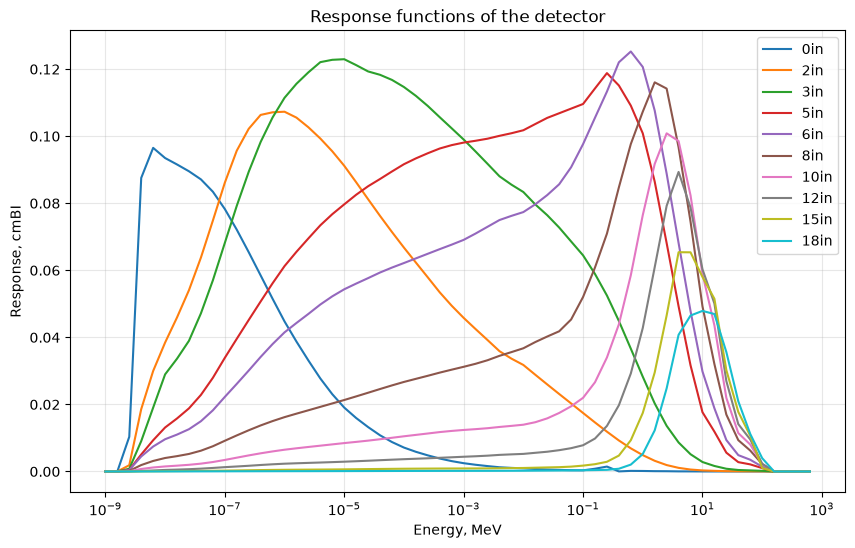

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bssunfold import Detector, RF_GSF
from bssunfold.utils.comparison import compare_spectra

detector = Detector(RF_GSF)
E = detector.E_MeV
names = detector.detector_names
print(f"Detector grid: {detector.n_energy_bins} bins, "
      f"{E[0]:.1e} - {E[-1]:.1f} MeV")
print("Spheres:", ", ".join(names))
detector.plot_response_functions()

## 2. IAEA Compendium reference spectrum -> detector readings

The compendium CSV stores 61-point Monte-Carlo spectra on its own energy grid,
which differs slightly from the 60-bin detector grid, so the ground truth is
interpolated onto the detector grid *for evaluation only*.  The readings are the
spectrum folded with the response functions, i.e. noise-free synthetic data.

In [2]:
reference_csv = pd.read_csv(
    '../tests/MonteCarlo_Calculated_spectra_from_IAEA_Comp_for_comparison.csv'
)
SPECTRUM = 't4-14-s.txt_1'   # IAEA Compendium BSA benchmark case

readings = detector.get_effective_readings_for_spectra(
    reference_csv[['E_MeV', SPECTRUM]]
)
phi_true = np.interp(
    E, reference_csv['E_MeV'].values, reference_csv[SPECTRUM].values
)

print("Effective readings:")
for nm in names:
    print(f"  {nm:>5s}: {readings[nm]:.4g}")

Effective readings:
    0in: 0.06677
    2in: 0.0901
    3in: 0.1382
    5in: 0.1639
    6in: 0.1407
    8in: 0.08047
   10in: 0.03924
   12in: 0.01789
   15in: 0.006419
   18in: 0.003085


## 3. Two exponents: Hölder versus Lipschitz

`mu` is the only shape knob of the method.  A small exponent prices a jump and a
ramp of the same height almost identically (all distances cost about 1), which is
what lets the method keep sharp structures; `mu = 1` is the Lipschitz case, where
a jump across one cell costs $1/h$ and is therefore strongly suppressed.

variant                       score  pearson_r  rel.flux   residual
Vasin, mu=0.1                 0.297      0.665     0.630   3.06e-13
Vasin, mu=1.0                 0.392      0.593     0.689   7.89e-04


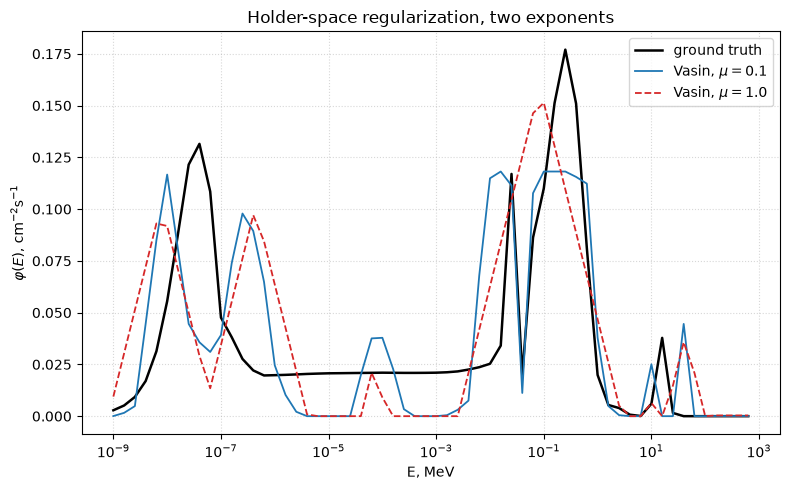

In [5]:
result_holder = detector.unfold_vasin(readings, mu=0.1, save_result=False)
result_lipschitz = detector.unfold_vasin(readings, mu=1.0, save_result=False)

print(f"{'variant':<26s} {'score':>8s} {'pearson_r':>10s} {'rel.flux':>9s} "
      f"{'residual':>10s}")
for label, res in [(f"Vasin, mu={result_holder['mu']:g}", result_holder),
                   ("Vasin, mu=1.0", result_lipschitz)]:
    m = compare_spectra(phi_true, res['spectrum'],
                        metrics=['comprehensive_score', 'pearson_r',
                                 'relative_flux_error'])
    print(f"{label:<26s} {m['comprehensive_score']:>8.3f} "
          f"{m['pearson_r']:>10.3f} {m['relative_flux_error']:>9.3f} "
          f"{res['residual_norm']:>10.2e}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(E, phi_true, 'k-', lw=1.8, label='ground truth')
ax.plot(E, result_holder['spectrum'], 'C0-', lw=1.3,
          label=r'Vasin, $\mu=0.1$')
ax.plot(E, result_lipschitz['spectrum'], 'C3--', lw=1.3,
          label=r'Vasin, $\mu=1.0$')
ax.set_xscale('log')
ax.set(xlabel='E, MeV', ylabel=r'$\varphi(E)$, cm$^{-2}$s$^{-1}$',
       title='Holder-space regularization, two exponents')
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

## 4. Regularization sweep over `alpha` and `mu`

On Bonner-sphere data the system is underdetermined (10 detectors, 60 energy
bins) and a non-negative *exact* fit exists, so the Chebyshev discrepancy can be
driven to zero.  On that solution face the achievable discrepancy is $0$ for any
$\alpha$, and $\alpha$ drops out of the trade-off: the spectra below differ by
about the solver tolerance for `alpha <= 1e-2` and only start to move once
$\alpha$ is large enough to make the stabilizer itself expensive.  `mu` carries
all of the regularization.  $\alpha$ regains influence as soon as the readings
are inconsistent (noise, dead-time corrections) and the discrepancy can no longer
be made zero; it is also what regularizes the Monte-Carlo replicates.

In [6]:
import warnings

reference = detector.unfold_vasin(readings, alpha=1e-2, mu=0.1, save_result=False)
print(f"{'alpha':>8s} {'relative shift vs alpha=1e-2':>32s}")
with warnings.catch_warnings():
    # Small alpha sits exactly on the zero-discrepancy face, where the objective
    # is orders of magnitude below the readings; solvers report that as a
    # slightly inaccurate optimum even though the spectrum is unchanged.
    warnings.simplefilter('ignore')
    for alpha in (1e-4, 1e-3, 1e-2, 1e-1, 1.0):
        res = detector.unfold_vasin(readings, alpha=alpha, mu=0.1,
                                    save_result=False)
        shift = np.linalg.norm(res['spectrum'] - reference['spectrum']) / \
            np.linalg.norm(reference['spectrum'])
        print(f"{alpha:>8.0e} {shift:>32.2e}")

   alpha     relative shift vs alpha=1e-2
   1e-04                         1.27e-03
   1e-03                         8.26e-04
   1e-02                         0.00e+00
   1e-01                         3.87e-01
   1e+00                         6.20e-01


In [7]:
print(f"{'alpha':>7s} {'mu':>6s} {'score':>8s} {'pearson_r':>10s} "
      f"{'rel.flux':>9s} {'residual':>10s}")
for alpha in (1e-2, 1e-1, 1.0):
    for mu in (0.05, 0.1, 0.5, 1.0):
        res = detector.unfold_vasin(readings, alpha=alpha, mu=mu,
                                    save_result=False)
        m = compare_spectra(phi_true, res['spectrum'],
                            metrics=['comprehensive_score', 'pearson_r',
                                     'relative_flux_error'])
        print(f"{alpha:>7.0e} {mu:>6g} {m['comprehensive_score']:>8.3f} "
              f"{m['pearson_r']:>10.3f} {m['relative_flux_error']:>9.3f} "
              f"{res['residual_norm']:>10.2e}")

  alpha     mu    score  pearson_r  rel.flux   residual
  1e-02   0.05    0.283      0.673     0.620   4.03e-13
  1e-02    0.1    0.297      0.665     0.630   3.06e-13
  1e-02    0.5    0.380      0.609     0.685   9.31e-12
  1e-02      1    0.392      0.593     0.689   7.89e-04
  1e-01   0.05    0.361      0.602     0.662   7.95e-04
  1e-01    0.1    0.372      0.595     0.669   9.08e-04
  1e-01    0.5    0.294      0.651     0.620   1.51e-03
  1e-01      1    0.320      0.618     0.629   6.53e-03
  1e+00   0.05    0.378      0.550     0.653   8.18e-03
  1e+00    0.1    0.379      0.548     0.653   8.45e-03
  1e+00    0.5    0.401      0.516     0.659   1.99e-02
  1e+00      1    0.689      0.181     0.779   4.77e-02


## 5. Where the method earns its keep: a spectrum with a real edge

The IAEA benchmark spectrum is smooth, so a smooth-penalty method is hard to beat
there.  The article's claim concerns *irregular* solutions, so this cell folds a
synthetic spectrum with an explicit discontinuity — a rectangular block on top of
a thermal spike — and unfolds it with the Hölder stabilizer and with plain
Tikhonov (identity penalty, non-negative least squares).

`transition bins` counts the energy bins whose value lies strictly between 20 %
and 80 % of the block height: for the ground truth itself the answer is 1, and a
larger number means a smeared edge.  The quadratic penalty spreads the flank over
three times as many bins as the Hölder one, while the aggregate score still
favours the smoother `mu = 1.0` variant — the usual bias/variance trade-off of a
discontinuity-friendly prior.

spectrum          transition bins    score  pearson_r
ground truth                    1
Vasin, mu=0.02                  4   -0.153      0.860
Vasin, mu=0.1                   4   -0.136      0.847
Vasin, mu=1.0                  15    0.126      0.589
Tikhonov (L2)                  12   -0.047      0.770


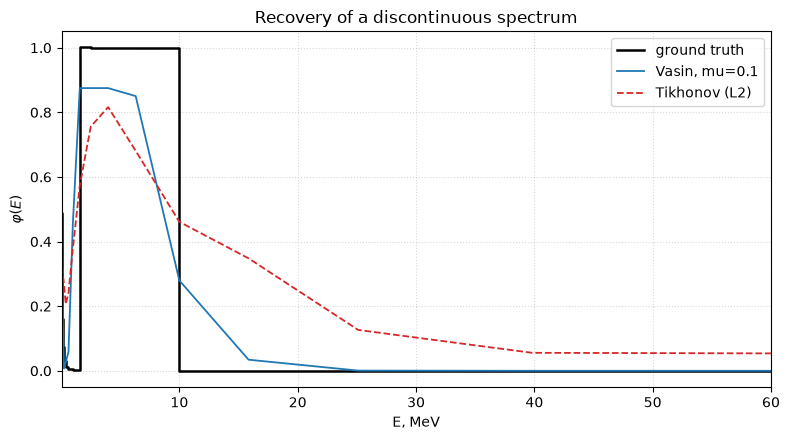

In [8]:
phi_sharp = (
    0.8 / (1.0 + (E / 0.05) ** 2)          # thermal spike
    + 1.0 * ((E > 1.0) & (E < 10.0))       # discontinuous block
)
readings_sharp = detector.get_effective_readings_for_spectra(
    pd.DataFrame({'E_MeV': E, 'phi': phi_sharp})
)


def transition_bins(spec, low=0.2, high=0.8):
    """Bins between the 20 % and 80 % levels of the block (1 for a step)."""
    inside = (E > 0.05) & (E < 60.0)
    values = spec[inside]
    return int(np.count_nonzero((values > low) & (values < high)))


candidates = [
    ('Vasin, mu=0.02', detector.unfold_vasin(readings_sharp, mu=0.02,
                                             save_result=False)['spectrum']),
    ('Vasin, mu=0.1', detector.unfold_vasin(readings_sharp, mu=0.1,
                                            save_result=False)['spectrum']),
    ('Vasin, mu=1.0', detector.unfold_vasin(readings_sharp, mu=1.0,
                                            save_result=False)['spectrum']),
    ('Tikhonov (L2)', detector.unfold_qpsolvers(readings_sharp, regularization=1e-6,
                                                 save_result=False)['spectrum']),
]

print(f"{'spectrum':<16s} {'transition bins':>16s} {'score':>8s} {'pearson_r':>10s}")
print(f"{'ground truth':<16s} {transition_bins(phi_sharp):>16d}")
for label, spec in candidates:
    m = compare_spectra(phi_sharp, spec,
                        metrics=['comprehensive_score', 'pearson_r'])
    print(f"{label:<16s} {transition_bins(spec):>16d} "
          f"{m['comprehensive_score']:>8.3f} {m['pearson_r']:>10.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.step(E, phi_sharp, 'k-', lw=1.8, where='post', label='ground truth')
ax.plot(E, candidates[1][1], 'C0-', lw=1.3, label='Vasin, mu=0.1')
ax.plot(E, candidates[3][1], 'C3--', lw=1.3, label='Tikhonov (L2)')
ax.set(xlabel='E, MeV', ylabel=r'$\varphi(E)$',
       title='Recovery of a discontinuous spectrum')
ax.set_xlim(0.05, 60)
ax.grid(True, which='both', ls=':', alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

## 6. Baselines

**GRAVEL** (weighted log-domain least squares) and **MLEM** start from the same
flat prior for comparison, together with the dose-rate estimates the unfolding
produces for the IAEA spectrum.

In [9]:
grav = detector.unfold_gravel(
    readings, initial_spectrum=np.full(E.size, 0.5),
    max_iterations=2000, save_result=False,
)
mlem = detector.unfold_mlem(
    readings, initial_spectrum=np.full(E.size, 0.5),
    max_iterations=2000, save_result=False,
)

labels = ['Vasin (mu=0.1)', 'Vasin (mu=1.0)', 'GRAVEL', 'MLEM']
results = [result_holder, result_lipschitz, grav, mlem]
print(f"{'method':<16s} {'score':>8s} {'pearson_r':>10s} {'rel.flux':>9s} "
      f"{'dose AP':>12s}")
for label, res in zip(labels, results):
    m = compare_spectra(phi_true, res['spectrum'],
                        metrics=['comprehensive_score', 'pearson_r',
                                 'relative_flux_error'])
    print(f"{label:<16s} {m['comprehensive_score']:>8.3f} "
          f"{m['pearson_r']:>10.3f} {m['relative_flux_error']:>9.3f} "
          f"{res['doserates']['AP']:>12.4g}")

method              score  pearson_r  rel.flux      dose AP
Vasin (mu=0.1)      0.297      0.665     0.630        56.81
Vasin (mu=1.0)      0.392      0.593     0.689        59.39
GRAVEL              2.954     -0.146     2.881        441.1
MLEM                0.008      0.834     0.425        60.07


## 7. Summary

* `unfold_vasin` minimizes the Vasin-Serazhitnikova functional: a Chebyshev
  discrepancy plus the non-differentiable stabilizer
  $\tfrac12 \sum_j h_j u_j^2 + \|u\|_\infty + [u]_{\mu,\infty}$, with
  non-negativity imposed as a constraint.
* The minimization is exact (epigraph conic program, CVXPY/CLARABEL) rather than
  the article's prox + subgradient iteration; the target functional is the same.
* `mu` is the shape knob.  Small `mu` (default 0.1) is Hölder-like and tolerant of
  jumps; `mu = 1` is Lipschitz and suppresses them.  With `mu -> 0` the seminorm
  degenerates to the oscillation $\max u - \min u$.
* On underdetermined, consistent data a non-negative exact fit exists, so `alpha`
  drops out of the trade-off and only `mu` matters; `alpha` becomes a real
  parameter as soon as the readings are inconsistent.
* The `\|u\|_\infty` term biases peak heights downward — visible in section 3 and
  5 — which is the price of a stabilizer that is cheap for discontinuities.
* The epigraph program carries $n(n-1)$ seminorm constraints, so cost grows
  quadratically with the number of energy bins; at $n = 60$ a solve takes about
  30 ms.
* Statistical uncertainties come from Monte-Carlo propagation
  (`calculate_errors=True`); `initial_spectrum` is accepted but ignored, since the
  functional has no a-priori term.